In [1]:
import torch
import torchvision
from torchvision.ops import nms

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "CUDA is unavailable."

print("GPU:", torch.cuda.get_device_name(0))
print("Capability:", torch.cuda.get_device_capability(0))

x = torch.randn(128, 128, device="cuda")
y = x @ x.T
torch.cuda.synchronize()
assert torch.isfinite(y).all()

boxes = torch.tensor(
    [[0, 0, 20, 20], [1, 1, 21, 21]],
    dtype=torch.float32,
    device="cuda",
)
scores = torch.tensor([0.9, 0.8], device="cuda")

kept = nms(boxes, scores, 0.5)
assert kept.cpu().tolist() == [0]

print("CUDA computation and TorchVision NMS passed.")

PyTorch: 2.7.1+cu126
TorchVision: 0.22.1+cu126
CUDA available: True
GPU: NVIDIA GeForce GTX 1080 Ti
Capability: (6, 1)
CUDA computation and TorchVision NMS passed.


In [2]:
from pathlib import Path

PROJECT_DIR = Path(r"H:\UCU\3_year\sem_1\artificial_intelligence\hw2")
DATA_ROOT = PROJECT_DIR
BASELINE_DIR = PROJECT_DIR / "faster_rcnn_baseline_fold0"

for split in ("train", "val"):
    path = DATA_ROOT / split / "annotations_coco.json"
    assert path.is_file(), f"Missing: {path}"

print("Dataset paths verified.")

print("\nSaved baseline files:")
for path in sorted(BASELINE_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name}: {path.stat().st_size / 1024**2:.2f} MiB")

Dataset paths verified.

Saved baseline files:
config.json: 0.00 MiB
last.pt: 329.83 MiB
train_folds.csv: 1.80 MiB


In [3]:
import torch

for filename in ("last.pt", "best.pt"):
    path = BASELINE_DIR / filename

    if not path.is_file():
        print(f"\n{filename}: missing")
        continue

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False,  # our own checkpoint
    )

    print(f"\n{filename}")
    print("Fold:", checkpoint["run_config"]["fold"])
    print("Completed validation epochs:", len(checkpoint["history"]))
    print("Global step:", checkpoint["global_step"])
    print("Best mAP:", checkpoint["best_map"])

    del checkpoint


last.pt
Fold: 0
Completed validation epochs: 0
Global step: 1000
Best mAP: -1.0

best.pt: missing


## Local Training and Recovery

We run Faster R-CNN locally on a GTX 1080 Ti using PyTorch 2.7.1
and TorchVision 0.22.1.

Our available legacy checkpoint contains 1,000 optimization steps
and no completed validation epoch. We preserve it separately.
We do not treat the five-epoch metrics recorded in the earlier
notebook as evidence that those model weights are available locally.

We store new experiments under runs/, with separate directories
for each configuration and fold. We save model, optimizer, scheduler,
random-number states, and training progress for recovery.

We resume from the latest successfully written checkpoint.
An abrupt interruption may require repeating steps performed after
that checkpoint. Local files persist across Python sessions, but
we retain backups to protect against disk loss.

In [4]:
import json
import random
import numpy as np
import torch
import torchvision

SEED = 42
DEVICE = torch.device("cuda:0")
RUNS_DIR = PROJECT_DIR / "runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

FOLDS_PATH = BASELINE_DIR / "train_folds.csv"
assert FOLDS_PATH.is_file(), f"Missing fold assignments: {FOLDS_PATH}"

LOCAL_CONFIG = {
    "seed": SEED,
    "folds": [0, 1, 2],
    "epochs": 5,
    "batch_size": 2,
    "num_workers": 0,
    "min_size": 640,
    "max_size": 1152,
    "checkpoint_every_steps": 250,
}

print("Runs directory:", RUNS_DIR)
print("Fold assignments:", FOLDS_PATH)
print("GPU:", torch.cuda.get_device_name(DEVICE))
print("Configuration:")
print(json.dumps(LOCAL_CONFIG, indent=2))

Runs directory: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs
Fold assignments: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\faster_rcnn_baseline_fold0\train_folds.csv
GPU: NVIDIA GeForce GTX 1080 Ti
Configuration:
{
  "seed": 42,
  "folds": [
    0,
    1,
    2
  ],
  "epochs": 5,
  "batch_size": 2,
  "num_workers": 0,
  "min_size": 640,
  "max_size": 1152,
  "checkpoint_every_steps": 250
}


## Dataset and Fixed Sequence-Level Folds

We reuse the saved fold assignments rather than generating a new split.
We verify that every training image appears exactly once and that
all frames from the same video belong to one fold.

We index annotations by image ID and load RGB images on demand.
We convert target boxes from COCO xywh to pixel-based xyxy coordinates.
We retain target labels 1–8 and keep ignored boxes separately.

Our baseline uses every assigned frame without random augmentation.
Image resizing and normalization are performed inside the detector.

In [5]:
from collections import defaultdict

import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms.functional import pil_to_tensor

with (DATA_ROOT / "train" / "annotations_coco.json").open(
    encoding="utf-8"
) as file:
    train_coco = json.load(file)

frames = pd.DataFrame(train_coco["images"]).rename(
    columns={"id": "image_id"}
)

saved_folds = pd.read_csv(FOLDS_PATH)

assert frames["image_id"].is_unique
assert saved_folds["image_id"].is_unique
assert set(frames["image_id"]) == set(saved_folds["image_id"])
assert saved_folds["fold"].isin(LOCAL_CONFIG["folds"]).all()
assert saved_folds.groupby("video")["fold"].nunique().eq(1).all()

verification = frames[
    ["image_id", "video", "frame_id", "file_name"]
].merge(
    saved_folds[
        ["image_id", "video", "frame_id", "file_name", "fold"]
    ],
    on="image_id",
    suffixes=("_current", "_saved"),
    validate="one_to_one",
)

for column in ("video", "frame_id", "file_name"):
    assert verification[f"{column}_current"].eq(
        verification[f"{column}_saved"]
    ).all(), f"Saved fold metadata mismatch: {column}"

train_frames = frames.merge(
    saved_folds[["image_id", "fold"]],
    on="image_id",
    validate="one_to_one",
).sort_values(
    ["video", "frame_id", "image_id"]
).reset_index(drop=True)

category_ids = {category["id"] for category in train_coco["categories"]}
assert category_ids == set(range(1, 9))

targets_by_image = defaultdict(list)
ignored_by_image = defaultdict(list)

for annotation in train_coco["annotations"]:
    assert annotation["image_id"] in category_image_ids if False else True
    ignored = (
        annotation.get("iscrowd", 0) == 1
        or annotation.get("ignore", 0) == 1
    )

    if ignored:
        ignored_by_image[annotation["image_id"]].append(annotation)
    else:
        assert annotation["category_id"] in category_ids
        targets_by_image[annotation["image_id"]].append(annotation)

known_image_ids = set(train_frames["image_id"])
assert set(targets_by_image).issubset(known_image_ids)
assert set(ignored_by_image).issubset(known_image_ids)


def coco_to_xyxy(records):
    boxes = torch.tensor(
        [record["bbox"] for record in records],
        dtype=torch.float32,
    ).reshape(-1, 4)

    boxes[:, 2:] += boxes[:, :2]
    return boxes


class VisDroneDataset(Dataset):
    def __init__(self, frame_table):
        self.frames = frame_table.reset_index(drop=True)

    def __len__(self):
        return len(self.frames)

    def __getitem__(self, index):
        row = self.frames.iloc[index]
        image_id = int(row["image_id"])
        image_path = DATA_ROOT / "train" / row["file_name"]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

            assert image.size == (
                int(row["width"]), int(row["height"])
            ), f"Image dimensions mismatch: {image_path}"

            image = pil_to_tensor(image).float().div_(255)

        records = targets_by_image.get(image_id, [])
        boxes = coco_to_xyxy(records)

        target = {
            "boxes": boxes,
            "labels": torch.tensor(
                [record["category_id"] for record in records],
                dtype=torch.int64,
            ),
            "image_id": torch.tensor(image_id, dtype=torch.int64),
            "area": (
                (boxes[:, 2] - boxes[:, 0])
                * (boxes[:, 3] - boxes[:, 1])
            ),
            "iscrowd": torch.zeros(len(boxes), dtype=torch.int64),
            "ignore_boxes": coco_to_xyxy(
                ignored_by_image.get(image_id, [])
            ),
        }

        return image, target


def detection_collate(batch):
    images, targets = zip(*batch)
    return list(images), list(targets)


ACTIVE_FOLD = 0

fit_frames = train_frames.loc[
    train_frames["fold"].ne(ACTIVE_FOLD)
].copy()

holdout_frames = train_frames.loc[
    train_frames["fold"].eq(ACTIVE_FOLD)
].copy()

assert set(fit_frames["video"]).isdisjoint(holdout_frames["video"])

fit_dataset = VisDroneDataset(fit_frames)
holdout_dataset = VisDroneDataset(holdout_frames)

debug_loader = DataLoader(
    fit_dataset,
    batch_size=LOCAL_CONFIG["batch_size"],
    shuffle=False,
    num_workers=0,
    collate_fn=detection_collate,
)

images, targets = next(iter(debug_loader))

display(
    train_frames.groupby("fold").agg(
        clips=("video", "nunique"),
        frames=("image_id", "size"),
    )
)

for index, (image, target) in enumerate(zip(images, targets)):
    assert torch.isfinite(image).all()
    assert image.min() >= 0 and image.max() <= 1
    assert torch.isfinite(target["boxes"]).all()
    assert (target["boxes"][:, 2:] > target["boxes"][:, :2]).all()

    print(
        f"Sample {index}: shape={tuple(image.shape)}, "
        f"targets={len(target['boxes'])}, "
        f"ignored={len(target['ignore_boxes'])}"
    )

print("Local dataset and fold checks passed.")

,clips,frames
fold,,
0,19,8080
1,19,8082
2,18,8039


Sample 0: shape=(3, 756, 1344), targets=23, ignored=32
Sample 1: shape=(3, 756, 1344), targets=23, ignored=32
Local dataset and fold checks passed.


## Ignore-Aware Target Assignment

We preserve annotated target objects even when they overlap ignored
regions. We exclude background candidates when at least 50% of their
area overlaps an ignored region.

We apply this rule after standard target assignment in both the RPN
and RoI heads. Covered background candidates receive label -1 and
are excluded from sampling; positive assignments remain unchanged.

We also resize ignored boxes alongside target boxes. We retain the
standard inference procedure, including greedy non-maximum suppression.

In [6]:
from torchvision.models.detection.transform import (
    GeneralizedRCNNTransform,
    resize_boxes,
)
from torchvision.models.detection.rpn import RegionProposalNetwork
from torchvision.models.detection.roi_heads import RoIHeads

IGNORE_IOA_THRESHOLD = 0.5


def max_ignore_ioa(candidate_boxes, ignore_boxes, chunk_size=4096):
    """Maximum intersection / candidate area over ignored boxes."""
    candidates = candidate_boxes.float()
    ignored = ignore_boxes.to(
        device=candidates.device,
        dtype=torch.float32,
    )

    overlaps = candidates.new_zeros(len(candidates))

    if len(candidates) == 0 or len(ignored) == 0:
        return overlaps

    for start in range(0, len(candidates), chunk_size):
        boxes = candidates[start:start + chunk_size]

        top_left = torch.maximum(
            boxes[:, None, :2], ignored[None, :, :2]
        )
        bottom_right = torch.minimum(
            boxes[:, None, 2:], ignored[None, :, 2:]
        )
        intersection = (
            (bottom_right - top_left).clamp(min=0).prod(dim=-1)
        )
        area = (
            (boxes[:, 2:] - boxes[:, :2])
            .clamp(min=0)
            .prod(dim=-1)
        )

        overlaps[start:start + len(boxes)] = (
            intersection / area.clamp_min(1e-6)[:, None]
        ).amax(dim=1)

    return overlaps


def exclude_ignored_background(labels, boxes, ignored, threshold):
    overlaps = max_ignore_ioa(boxes, ignored)
    updated = labels.clone()
    updated[labels.eq(0) & overlaps.ge(threshold)] = -1
    return updated


class IgnoreAwareTransform(GeneralizedRCNNTransform):
    def resize(self, image, target=None):
        original_size = image.shape[-2:]

        if target is not None:
            target = target.copy()
            ignored = target.get("ignore_boxes")
        else:
            ignored = None

        image, target = super().resize(image, target)

        if ignored is not None:
            target["ignore_boxes"] = resize_boxes(
                ignored, original_size, image.shape[-2:]
            )

        return image, target


class IgnoreAwareRPN(RegionProposalNetwork):
    ignore_ioa_threshold = IGNORE_IOA_THRESHOLD

    def assign_targets_to_anchors(self, anchors, targets):
        labels, matched_boxes = super().assign_targets_to_anchors(
            anchors, targets
        )

        labels = [
            exclude_ignored_background(
                image_labels,
                image_anchors,
                target["ignore_boxes"],
                self.ignore_ioa_threshold,
            )
            for image_labels, image_anchors, target
            in zip(labels, anchors, targets)
        ]

        return labels, matched_boxes


class IgnoreAwareRoIHeads(RoIHeads):
    ignore_ioa_threshold = IGNORE_IOA_THRESHOLD

    def select_training_samples(self, proposals, targets):
        self._active_ignore_boxes = [
            target["ignore_boxes"] for target in targets
        ]
        try:
            return super().select_training_samples(proposals, targets)
        finally:
            del self._active_ignore_boxes

    def assign_targets_to_proposals(
        self, proposals, gt_boxes, gt_labels
    ):
        matched_indices, labels = (
            super().assign_targets_to_proposals(
                proposals, gt_boxes, gt_labels
            )
        )

        ignored_per_image = getattr(
            self, "_active_ignore_boxes", None
        )

        if ignored_per_image is not None:
            labels = [
                exclude_ignored_background(
                    image_labels,
                    image_proposals,
                    ignored,
                    self.ignore_ioa_threshold,
                )
                for image_labels, image_proposals, ignored
                in zip(labels, proposals, ignored_per_image)
            ]

        return matched_indices, labels

In [7]:
candidate_boxes = torch.tensor(
    [
        [10, 10, 20, 20],      # inside ignored region
        [90, 0, 110, 20],      # 50% inside
        [110, 110, 120, 120],  # outside
    ],
    dtype=torch.float32,
    device=DEVICE,
)
ignored_boxes = torch.tensor(
    [[0, 0, 100, 100]],
    dtype=torch.float32,
    device=DEVICE,
)
labels = torch.tensor([0, 3, 0], device=DEVICE)

ioa = max_ignore_ioa(candidate_boxes, ignored_boxes)
updated = exclude_ignored_background(
    labels, candidate_boxes, ignored_boxes, IGNORE_IOA_THRESHOLD
)

torch.testing.assert_close(
    ioa, torch.tensor([1.0, 0.5, 0.0], device=DEVICE)
)
assert updated.cpu().tolist() == [-1, 3, 0]

print("IoA:", ioa.cpu().tolist())
print("Updated labels:", updated.cpu().tolist())
print("Ignore-aware assignment check passed.")

IoA: [1.0, 0.5, 0.0]
Updated labels: [-1, 3, 0]
Ignore-aware assignment check passed.


## Pretrained Faster R-CNN and Local Smoke Test

We initialize Faster R-CNN ResNet-50 FPN V2 with COCO-pretrained
weights and replace the prediction head for eight target classes
plus background.

We integrate ignore-aware resizing and target assignment into the
existing detector components while preserving their pretrained weights.

Our baseline resizes the shorter image side to 640 pixels, subject
to a maximum longer side of 1152 pixels. We retain the default anchors
and allow up to 500 final detections per image.

We verify ignored-box scaling and a complete forward/backward pass
on our local GPU. This diagnostic does not update model parameters
or measure detection accuracy.

In [8]:
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn_v2,
    FasterRCNN_ResNet50_FPN_V2_Weights,
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

MODEL_CONFIG = {
    "num_classes": 9,
    "min_size": LOCAL_CONFIG["min_size"],
    "max_size": LOCAL_CONFIG["max_size"],
    "box_detections_per_img": 500,
    "box_score_thresh": 0.001,
    "ignore_ioa_threshold": IGNORE_IOA_THRESHOLD,
}


def build_faster_rcnn(config):
    model = fasterrcnn_resnet50_fpn_v2(
        weights=FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT,
        min_size=config["min_size"],
        max_size=config["max_size"],
        box_detections_per_img=config["box_detections_per_img"],
        box_score_thresh=config["box_score_thresh"],
    )

    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(
        in_features,
        config["num_classes"],
    )

    # Preserve initialized parameters and configuration while replacing
    # the relevant methods with our ignore-aware implementations.
    model.transform.__class__ = IgnoreAwareTransform
    model.rpn.__class__ = IgnoreAwareRPN
    model.roi_heads.__class__ = IgnoreAwareRoIHeads

    model.rpn.ignore_ioa_threshold = config["ignore_ioa_threshold"]
    model.roi_heads.ignore_ioa_threshold = config["ignore_ioa_threshold"]

    return model

In [9]:
import time
import gc

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

smoke_model = build_faster_rcnn(MODEL_CONFIG).to(DEVICE)
smoke_model.train()

smoke_images = [
    image.to(DEVICE) for image in images
]
smoke_targets = [
    {
        key: value.to(DEVICE)
        for key, value in target.items()
    }
    for target in targets
]

with torch.no_grad():
    transformed_images, transformed_targets = smoke_model.transform(
        smoke_images, smoke_targets
    )

    for original_image, original_target, resized_size, resized_target in zip(
        smoke_images,
        smoke_targets,
        transformed_images.image_sizes,
        transformed_targets,
    ):
        expected = resize_boxes(
            original_target["ignore_boxes"],
            original_image.shape[-2:],
            resized_size,
        )
        torch.testing.assert_close(
            resized_target["ignore_boxes"], expected
        )

del transformed_images, transformed_targets, expected

torch.cuda.reset_peak_memory_stats(DEVICE)
torch.cuda.synchronize()
started = time.perf_counter()

smoke_model.zero_grad(set_to_none=True)
losses = smoke_model(smoke_images, smoke_targets)
total_loss = sum(losses.values())

assert torch.isfinite(total_loss), "Non-finite loss."

total_loss.backward()

gradient = smoke_model.roi_heads.box_predictor.cls_score.weight.grad
assert gradient is not None
assert torch.isfinite(gradient).all()

torch.cuda.synchronize()

for name, value in losses.items():
    print(f"{name}: {value.detach().item():.4f}")

print(f"Total loss: {total_loss.detach().item():.4f}")
print(f"Forward/backward time: {time.perf_counter() - started:.2f} s")
print(
    "Peak allocated GPU memory:",
    f"{torch.cuda.max_memory_allocated(DEVICE) / 1024**3:.2f} GiB",
)

# Discard the diagnostic model, including any updated BatchNorm statistics.
del smoke_model, smoke_images, smoke_targets
del losses, total_loss, gradient
gc.collect()
torch.cuda.empty_cache()

print("Local Faster R-CNN smoke test passed. No optimizer step performed.")

loss_classifier: 2.4035
loss_box_reg: 0.7520
loss_objectness: 0.0927
loss_rpn_box_reg: 0.1167
Total loss: 3.3650
Forward/backward time: 0.64 s
Peak allocated GPU memory: 3.00 GiB
Local Faster R-CNN smoke test passed. No optimizer step performed.


## Ignore-Aware COCO Evaluation

We evaluate predictions in original-image coordinates using COCO
category IDs 1–8.

We represent each class-independent ignored region as a crowd
annotation for every target category. This is our local adaptation
of COCO evaluation; we do not assume exact equivalence to the
competition scorer.

We report mAP, AP50, AP75, size-specific AP, and per-class AP.
We distinguish standard maxDets=100 results from additional
maxDets=500 results.

We validate the evaluator on a synthetic example before using it
for checkpoint selection.

In [10]:
import copy
import contextlib
import io

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval


def build_eval_coco(source, image_ids):
    image_ids = set(map(int, image_ids))
    category_ids = sorted(
        category["id"] for category in source["categories"]
    )

    output_annotations = []

    for annotation in source["annotations"]:
        if annotation["image_id"] not in image_ids:
            continue

        ignored = (
            annotation.get("iscrowd", 0) == 1
            or annotation.get("ignore", 0) == 1
        )

        evaluation_categories = (
            category_ids if ignored
            else [annotation["category_id"]]
        )

        for category_id in evaluation_categories:
            item = {
                "id": len(output_annotations) + 1,
                "image_id": annotation["image_id"],
                "category_id": category_id,
                "bbox": list(annotation["bbox"]),
                "area": float(
                    annotation["bbox"][2] * annotation["bbox"][3]
                ),
                "iscrowd": int(ignored),
            }
            output_annotations.append(item)

    coco = COCO()
    coco.dataset = {
        "info": {"description": "Local ignore-aware evaluation"},
        "images": [
            dict(image)
            for image in source["images"]
            if image["id"] in image_ids
        ],
        "categories": copy.deepcopy(source["categories"]),
        "annotations": output_annotations,
    }

    assert len(coco.dataset["images"]) == len(image_ids)

    with contextlib.redirect_stdout(io.StringIO()):
        coco.createIndex()

    return coco


def evaluate_coco_predictions(coco_gt, predictions, max_dets=100):
    print(
        f"COCO evaluation: {len(coco_gt.imgs):,} images, "
        f"{len(predictions):,} predictions, maxDets={max_dets}",
        flush=True,
    )
    started = time.perf_counter()

    with contextlib.redirect_stdout(io.StringIO()):
        if predictions:
            coco_dt = coco_gt.loadRes(predictions)
        else:
            coco_dt = COCO()
            coco_dt.dataset = {
                "images": list(coco_gt.imgs.values()),
                "categories": list(coco_gt.cats.values()),
                "annotations": [],
            }
            coco_dt.createIndex()

        evaluator = COCOeval(coco_gt, coco_dt, iouType="bbox")
        evaluator.params.imgIds = sorted(coco_gt.imgs)
        evaluator.params.catIds = sorted(coco_gt.cats)
        evaluator.params.maxDets = [1, 10, max_dets]

        evaluator.evaluate()
        evaluator.accumulate()

    precision = evaluator.eval["precision"]

    def mean_valid(values):
        values = values[values >= 0]
        return float(values.mean()) if values.size else float("nan")

    area_index = {
        name: index
        for index, name in enumerate(evaluator.params.areaRngLbl)
    }
    iou50 = np.flatnonzero(
        np.isclose(evaluator.params.iouThrs, 0.50)
    )[0]
    iou75 = np.flatnonzero(
        np.isclose(evaluator.params.iouThrs, 0.75)
    )[0]
    all_area = area_index["all"]

    metrics = {
        "mAP": mean_valid(precision[:, :, :, all_area, -1]),
        "AP50": mean_valid(precision[iou50, :, :, all_area, -1]),
        "AP75": mean_valid(precision[iou75, :, :, all_area, -1]),
        "AP_small": mean_valid(
            precision[:, :, :, area_index["small"], -1]
        ),
        "AP_medium": mean_valid(
            precision[:, :, :, area_index["medium"], -1]
        ),
        "AP_large": mean_valid(
            precision[:, :, :, area_index["large"], -1]
        ),
        "max_dets": max_dets,
    }

    per_class = {
        coco_gt.cats[category_id]["name"]: mean_valid(
            precision[:, :, index, all_area, -1]
        )
        for index, category_id in enumerate(evaluator.params.catIds)
    }

    print(
        f"COCO evaluation finished in "
        f"{(time.perf_counter() - started) / 60:.2f} min.",
        flush=True,
    )

    return metrics, per_class

In [11]:
# Preserve the original evaluator; do not wrap it recursively.
if "_evaluate_coco_original" not in globals():
    _evaluate_coco_original = evaluate_coco_predictions


def evaluate_coco_predictions(coco_gt, predictions, max_dets=100):
    # Keep compatibility with the original synthetic tests.
    if not isinstance(predictions, np.ndarray):
        return _evaluate_coco_original(
            coco_gt, predictions, max_dets=max_dets
        )

    if predictions.ndim != 2 or predictions.shape[1] != 7:
        raise ValueError("Expected an array with seven columns.")

    started = time.perf_counter()
    category_metrics = []
    per_class = {}

    for category_id in sorted(coco_gt.cats):
        category = coco_gt.cats[category_id]

        # Reuse GT records without copying the entire annotation dataset.
        category_gt = COCO()
        category_gt.dataset = {
            "info": {},
            "images": list(coco_gt.imgs.values()),
            "categories": [category],
            "annotations": [
                annotation
                for annotation in coco_gt.anns.values()
                if annotation["category_id"] == category_id
            ],
        }

        with contextlib.redirect_stdout(io.StringIO()):
            category_gt.createIndex()

        selected = predictions[
            predictions[:, 1] == category_id
        ]

        category_predictions = [
            {
                "image_id": int(row[0]),
                "category_id": int(row[1]),
                "score": float(row[2]),
                "bbox": row[3:].tolist(),
            }
            for row in selected
        ]

        print(f"Evaluating class: {category['name']}")

        metrics, class_ap = _evaluate_coco_original(
            category_gt,
            category_predictions,
            max_dets=max_dets,
        )

        category_metrics.append(metrics)
        per_class[category["name"]] = class_ap[category["name"]]

        del category_gt, category_predictions, selected
        gc.collect()

    def average_defined(metric):
        values = np.asarray(
            [result[metric] for result in category_metrics],
            dtype=np.float64,
        )
        valid = np.isfinite(values)
        return float(values[valid].mean()) if valid.any() else float("nan")

    metrics = {
        name: average_defined(name)
        for name in (
            "mAP", "AP50", "AP75",
            "AP_small", "AP_medium", "AP_large",
        )
    }
    metrics["max_dets"] = max_dets

    print(
        "Class-wise evaluation finished in "
        f"{(time.perf_counter() - started) / 60:.2f} min."
    )

    return metrics, per_class

In [12]:
synthetic_source = {
    "images": [
        {"id": 1, "width": 200, "height": 200},
        {"id": 2, "width": 200, "height": 200},
    ],
    "categories": [
        {"id": 1, "name": "person"},
        {"id": 8, "name": "motor"},
    ],
    "annotations": [
        {
            "image_id": 1, "category_id": 1,
            "bbox": [10, 10, 20, 20], "iscrowd": 0,
        },
        {
            "image_id": 2, "category_id": 8,
            "bbox": [10, 10, 20, 20], "iscrowd": 0,
        },
        {
            "image_id": 1, "category_id": 1,
            "bbox": [100, 100, 80, 80], "iscrowd": 1,
        },
    ],
}

synthetic_gt = build_eval_coco(synthetic_source, [1, 2])

correct = [
    {
        "image_id": 1, "category_id": 1,
        "bbox": [10, 10, 20, 20], "score": 0.9,
    },
    {
        "image_id": 2, "category_id": 8,
        "bbox": [10, 10, 20, 20], "score": 0.9,
    },
]
ignored_prediction = {
    "image_id": 1, "category_id": 8,
    "bbox": [110, 110, 15, 15], "score": 0.99,
}
false_positive = {
    "image_id": 1, "category_id": 8,
    "bbox": [50, 50, 15, 15], "score": 0.995,
}

perfect, _ = evaluate_coco_predictions(synthetic_gt, correct)
with_ignore, _ = evaluate_coco_predictions(
    synthetic_gt, correct + [ignored_prediction]
)
with_fp, _ = evaluate_coco_predictions(
    synthetic_gt, correct + [ignored_prediction, false_positive]
)

assert np.isclose(perfect["mAP"], 1.0)
assert np.isclose(with_ignore["mAP"], 1.0)
assert np.isclose(with_fp["mAP"], 0.75)

print("Evaluator checks passed.")

COCO evaluation: 2 images, 2 predictions, maxDets=100
COCO evaluation finished in 0.00 min.
COCO evaluation: 2 images, 3 predictions, maxDets=100
COCO evaluation finished in 0.00 min.
COCO evaluation: 2 images, 4 predictions, maxDets=100
COCO evaluation finished in 0.00 min.
Evaluator checks passed.


In [13]:
test_predictions = correct + [ignored_prediction, false_positive]

test_array = np.asarray([
    [
        prediction["image_id"],
        prediction["category_id"],
        prediction["score"],
        *prediction["bbox"],
    ]
    for prediction in test_predictions
], dtype=np.float32)

reference_metrics, reference_classes = _evaluate_coco_original(
    synthetic_gt,
    test_predictions,
)

compact_metrics, compact_classes = evaluate_coco_predictions(
    synthetic_gt,
    test_array,
)

for name in reference_metrics:
    np.testing.assert_allclose(
        compact_metrics[name],
        reference_metrics[name],
        atol=1e-7,
        rtol=1e-6,
        equal_nan=True,
    )

for name in reference_classes:
    np.testing.assert_allclose(
        compact_classes[name],
        reference_classes[name],
        atol=1e-7,
        rtol=1e-6,
        equal_nan=True,
    )

print("Compact evaluator equivalence passed.")

COCO evaluation: 2 images, 4 predictions, maxDets=100
COCO evaluation finished in 0.00 min.
Evaluating class: person
COCO evaluation: 2 images, 1 predictions, maxDets=100
COCO evaluation finished in 0.00 min.
Evaluating class: motor
COCO evaluation: 2 images, 3 predictions, maxDets=100
COCO evaluation finished in 0.00 min.
Class-wise evaluation finished in 0.02 min.
Compact evaluator equivalence passed.


## Checkpointing and Recovery

We save model parameters and buffers, optimizer and scheduler states,
random-number states, completed training progress, and metric history.

We write each checkpoint to a temporary file and replace the destination
only after writing succeeds. We retain the previous checkpoint as a
fallback and store the best model separately.

We resume from the latest successfully saved training state.
An abrupt interruption may require repeating steps since the last
checkpoint. Local checkpointing does not protect against disk failure,
so we retain separate backups.

We record the training configuration and verify it before resuming.
We do not silently reuse checkpoints from a different experiment.

In [14]:
import os
import copy
import random
from pathlib import Path


def capture_rng_state():
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all(),
    }


def restore_rng_state(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"].cpu())

    saved_cuda = state["cuda"]
    current_count = torch.cuda.device_count()

    if len(saved_cuda) != current_count:
        raise RuntimeError(
            "GPU count differs from the checkpoint. "
            "Exact RNG restoration requires the same GPU count."
        )

    torch.cuda.set_rng_state_all([
        value.cpu() for value in saved_cuda
    ])


def atomic_torch_save(state, destination, keep_previous=True):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)

    temporary = destination.with_name(destination.name + ".tmp")
    previous = destination.with_name(
        destination.stem + ".previous" + destination.suffix
    )

    # Flush the completed file before replacing the current checkpoint.
    with temporary.open("wb") as file:
        torch.save(state, file)
        file.flush()
        os.fsync(file.fileno())

    if keep_previous and destination.exists():
        os.replace(destination, previous)

    os.replace(temporary, destination)


def load_checkpoint_with_fallback(path):
    """Load only our own trusted checkpoint files."""
    path = Path(path)
    previous = path.with_name(
        path.stem + ".previous" + path.suffix
    )

    errors = []

    for candidate in (path, previous):
        if not candidate.is_file():
            continue

        try:
            state = torch.load(
                candidate,
                map_location="cpu",
                weights_only=False,
            )
        except Exception as error:
            errors.append(f"{candidate.name}: {error}")
            continue

        print("Loaded checkpoint:", candidate)
        return state

    if errors:
        raise RuntimeError(
            "Checkpoint files could not be loaded:\n"
            + "\n".join(errors)
        )

    return None


def optimizer_to_device(optimizer, device):
    for parameter_state in optimizer.state.values():
        for key, value in parameter_state.items():
            if torch.is_tensor(value):
                parameter_state[key] = value.to(device)

In [15]:
import tempfile

with tempfile.TemporaryDirectory(dir=RUNS_DIR) as temporary_dir:
    test_path = Path(temporary_dir) / "last.pt"

    atomic_torch_save(
        {"global_step": 1, "value": torch.tensor([1.0])},
        test_path,
    )
    atomic_torch_save(
        {"global_step": 2, "value": torch.tensor([2.0])},
        test_path,
    )

    latest = load_checkpoint_with_fallback(test_path)
    assert latest["global_step"] == 2

    test_path.unlink()

    fallback = load_checkpoint_with_fallback(test_path)
    assert fallback["global_step"] == 1

print("Checkpoint writing and fallback checks passed.")

Loaded checkpoint: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\tmpc8yrqnvg\last.pt
Loaded checkpoint: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\tmpc8yrqnvg\last.previous.pt
Checkpoint writing and fallback checks passed.


## Experimental Protocol and Sequential Search

We use the same saved video-level folds, training frames, input
resolution, batch size, and five-epoch training horizon across
our initial comparisons.

We establish a baseline and investigate three changes:
- the number of RPN proposals retained after NMS;
- the learning-rate schedule;
- the second-stage box regression loss.

We perform a sequential greedy search on fold 0. At each stage,
we compare a candidate against the current incumbent under the
same protocol. We retain a change only when it improves validation
mAP, while also examining AP_small and computational cost.

Each candidate starts from the same COCO-pretrained initialization,
rather than continuing from the incumbent's trained weights.
This separates configuration changes from additional training.

We retain all intermediate results, including unsuccessful candidates.
We evaluate the baseline and selected configuration across all three
folds. Fold-0 search results are internal model-selection estimates;
the provided validation split is reserved for subsequent benchmarking.

Five epochs define our initial comparison budget, not proof of
convergence. We inspect learning curves before extending training.

In [16]:
BASE_TRAIN_CONFIG = {
    "seed": SEED,
    "epochs": LOCAL_CONFIG["epochs"],
    "batch_size": LOCAL_CONFIG["batch_size"],
    "num_workers": LOCAL_CONFIG["num_workers"],
    "checkpoint_every_steps": LOCAL_CONFIG["checkpoint_every_steps"],
    "lr": 0.005,
    "momentum": 0.9,
    "weight_decay": 0.0005,
    "warmup_steps": 1000,
    "warmup_start_factor": 0.1,
    "schedule": "plateau",
    "plateau_factor": 0.5,
    "plateau_patience": 2,
    "min_lr": 1e-5,
    "augmentation": "none",
}

BASE_MODEL_CONFIG = {
    **MODEL_CONFIG,
    "rpn_post_nms_top_n_train": 2000,
    "rpn_post_nms_top_n_test": 1000,
    "box_batch_size_per_image": 512,
    "box_positive_fraction": 0.25,
    "roi_box_loss": "smooth_l1",
}

# These are configuration specifications.
# The model/loss/scheduler implementations are connected next.
SEARCH_STAGES = [
    {
        "name": "rpn_proposals",
        "model_changes": {
            "rpn_post_nms_top_n_train": 4000,
            "rpn_post_nms_top_n_test": 2000,
        },
        "training_changes": {},
    },
    {
        "name": "cosine_schedule",
        "model_changes": {},
        "training_changes": {
            "schedule": "cosine",
        },
    },
    {
        "name": "giou_regression",
        "model_changes": {
            "roi_box_loss": "giou",
        },
        "training_changes": {},
    },
]

SEARCH_FOLD = 0
CV_FOLDS = list(LOCAL_CONFIG["folds"])

# A small AP gain alone is not strong evidence of generalization.
# We record any strict improvement during search and assess
# consistency afterward across the other folds.
SELECTION_METRIC = "mAP"

experiment_plan = pd.DataFrame([
    {
        "experiment": "baseline",
        "model_changes": "none",
        "training_changes": "none",
    },
    *[
        {
            "experiment": stage["name"],
            "model_changes": str(stage["model_changes"]),
            "training_changes": str(stage["training_changes"]),
        }
        for stage in SEARCH_STAGES
    ],
])

display(experiment_plan)
print("Search fold:", SEARCH_FOLD)
print("Cross-validation folds:", CV_FOLDS)
print("Epochs per initial run:", BASE_TRAIN_CONFIG["epochs"])
print("No training started.")

,experiment,model_changes,training_changes
0,baseline,none,none
1,rpn_proposals,"{'rpn_post_nms_top_n_train': 4000, 'rpn_post_n...",{}
2,cosine_schedule,{},{'schedule': 'cosine'}
3,giou_regression,{'roi_box_loss': 'giou'},{}


Search fold: 0
Cross-validation folds: [0, 1, 2]
Epochs per initial run: 5
No training started.


## Second-Stage Box Regression Loss

We compare the standard Smooth L1 regression loss with GIoU.
We retain the same classification loss and leave RPN losses unchanged.

Smooth L1 operates on encoded box offsets. For GIoU, we decode
predicted offsets and regression targets into image-space boxes.
We select the regression output corresponding to each positive
proposal's target class.

We normalize the summed GIoU loss by the total number of sampled
proposals, matching the normalization convention of the baseline
regression loss. The loss scales can still differ, so we inspect
their magnitudes and validation behavior.

In [17]:
import torch.nn.functional as F

from torchvision.ops import generalized_box_iou_loss
from torchvision.models.detection.roi_heads import fastrcnn_loss


def compute_roi_losses(
    class_logits,
    box_regression,
    labels,
    regression_targets,
    proposals,
    box_coder,
    loss_name,
):
    if loss_name == "smooth_l1":
        # Preserve TorchVision's original baseline loss.
        return fastrcnn_loss(
            class_logits,
            box_regression,
            labels,
            regression_targets,
        )

    if loss_name != "giou":
        raise ValueError(f"Unknown RoI regression loss: {loss_name}")

    flat_labels = torch.cat(labels, dim=0)

    classification_loss = F.cross_entropy(
        class_logits,
        flat_labels,
    )

    positive_indices = torch.where(flat_labels > 0)[0]

    if positive_indices.numel() == 0:
        # Keep a differentiable zero when no positive proposals exist.
        return classification_loss, box_regression.sum() * 0.0

    # Decode class-specific predictions: [N, num_classes, 4].
    predicted_boxes = box_coder.decode(
        box_regression.float(),
        proposals,
    )

    # Each regression target contains one encoded target box.
    target_boxes = box_coder.decode(
        torch.cat(regression_targets, dim=0).float(),
        proposals,
    ).reshape(-1, 4)

    positive_classes = flat_labels[positive_indices]

    selected_predictions = predicted_boxes[
        positive_indices,
        positive_classes,
    ]
    selected_targets = target_boxes[positive_indices]

    regression_loss = generalized_box_iou_loss(
        selected_predictions,
        selected_targets,
        reduction="sum",
    ) / flat_labels.numel()

    return classification_loss, regression_loss

In [18]:
from torchvision.models.detection._utils import BoxCoder

test_coder = BoxCoder(weights=(10.0, 10.0, 5.0, 5.0))

test_proposals = [
    torch.tensor(
        [
            [0, 0, 20, 20],
            [30, 30, 60, 70],
            [80, 80, 100, 100],
        ],
        dtype=torch.float32,
    )
]
test_labels = [torch.tensor([1, 2, 0], dtype=torch.int64)]

# Non-zero target offsets create imperfect positive predictions.
test_targets = [torch.full((3, 4), 0.2)]

test_logits = torch.zeros(3, 9, requires_grad=True)
test_regression = torch.zeros(3, 9 * 4, requires_grad=True)

classification_loss, regression_loss = compute_roi_losses(
    test_logits,
    test_regression,
    test_labels,
    test_targets,
    test_proposals,
    test_coder,
    loss_name="giou",
)

assert torch.isfinite(classification_loss)
assert torch.isfinite(regression_loss)
assert regression_loss.item() > 0

(classification_loss + regression_loss).backward()

assert torch.isfinite(test_regression.grad).all()
assert test_regression.grad[:2].abs().sum() > 0
assert test_regression.grad[2].eq(0).all()

# Background-only samples must produce a differentiable zero.
background_regression = torch.zeros(3, 9 * 4, requires_grad=True)

_, background_loss = compute_roi_losses(
    torch.zeros(3, 9, requires_grad=True),
    background_regression,
    [torch.zeros(3, dtype=torch.int64)],
    test_targets,
    test_proposals,
    test_coder,
    loss_name="giou",
)

background_loss.backward()
assert background_loss.item() == 0
assert background_regression.grad.eq(0).all()

print(f"Classification loss: {classification_loss.item():.4f}")
print(f"GIoU regression loss: {regression_loss.item():.4f}")
print("Positive gradients and background-only handling passed.")

Classification loss: 2.1972
GIoU regression loss: 0.0513
Positive gradients and background-only handling passed.


## Configurable Faster R-CNN

We expose RPN proposal limits and RoI sampling settings explicitly
so that experiment configurations control the actual model.

For the Smooth L1 baseline, we retain TorchVision's original RoI
forward implementation. For the GIoU experiment, we use the same
proposal sampling, feature pooling, box head, and predictor, replacing
only the second-stage regression loss.

We preserve ignore-aware target assignment in both cases.
Inference continues through TorchVision's standard implementation.
This implementation is specific to bounding-box detection.

In [19]:
class ConfigurableRoIHeads(IgnoreAwareRoIHeads):
    roi_box_loss = "smooth_l1"

    def forward(self, features, proposals, image_shapes, targets=None):
        # Preserve the original baseline and the standard inference path.
        if not self.training or self.roi_box_loss == "smooth_l1":
            return super().forward(
                features, proposals, image_shapes, targets
            )

        if self.roi_box_loss != "giou":
            raise ValueError(
                f"Unknown RoI regression loss: {self.roi_box_loss}"
            )

        if targets is None:
            raise ValueError("Training requires targets.")

        if self.has_mask() or self.has_keypoint():
            raise NotImplementedError(
                "The custom GIoU path supports bounding boxes only."
            )

        self.check_targets(targets)

        for target in targets:
            if target["labels"].dtype != torch.int64:
                raise TypeError("Target labels must use torch.int64.")
            if not target["boxes"].is_floating_point():
                raise TypeError("Target boxes must be floating point.")

        # Inherited sampling preserves our ignored-region handling.
        proposals, _, labels, regression_targets = (
            self.select_training_samples(proposals, targets)
        )

        box_features = self.box_roi_pool(
            features, proposals, image_shapes
        )
        box_features = self.box_head(box_features)
        class_logits, box_regression = self.box_predictor(box_features)

        classification_loss, regression_loss = compute_roi_losses(
            class_logits,
            box_regression,
            labels,
            regression_targets,
            proposals,
            self.box_coder,
            loss_name=self.roi_box_loss,
        )

        return [], {
            "loss_classifier": classification_loss,
            "loss_box_reg": regression_loss,
        }


def build_faster_rcnn(config, pretrained=True):
    model = fasterrcnn_resnet50_fpn_v2(
        weights=(
            FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
            if pretrained else None
        ),
        weights_backbone=None,
        min_size=config["min_size"],
        max_size=config["max_size"],
        box_detections_per_img=config["box_detections_per_img"],
        box_score_thresh=config["box_score_thresh"],
        rpn_post_nms_top_n_train=config["rpn_post_nms_top_n_train"],
        rpn_post_nms_top_n_test=config["rpn_post_nms_top_n_test"],
        box_batch_size_per_image=config["box_batch_size_per_image"],
        box_positive_fraction=config["box_positive_fraction"],
    )

    # Without pretrained weights, the constructor can change backbone
    # trainability defaults. Match our pretrained baseline explicitly.
    for name, parameter in model.backbone.body.named_parameters():
        parameter.requires_grad_(
            name.startswith(("layer2.", "layer3.", "layer4."))
        )

    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(
        in_features,
        config["num_classes"],
    )

    model.transform.__class__ = IgnoreAwareTransform
    model.rpn.__class__ = IgnoreAwareRPN
    model.roi_heads.__class__ = ConfigurableRoIHeads

    model.rpn.ignore_ioa_threshold = config["ignore_ioa_threshold"]
    model.roi_heads.ignore_ioa_threshold = config["ignore_ioa_threshold"]
    model.roi_heads.roi_box_loss = config["roi_box_loss"]

    return model

In [20]:
giou_check_config = {
    **BASE_MODEL_CONFIG,
    "roi_box_loss": "giou",
}

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

check_model = build_faster_rcnn(giou_check_config).to(DEVICE)
check_model.train()

check_images = [images[0].to(DEVICE)]
check_targets = [{
    key: value.to(DEVICE)
    for key, value in targets[0].items()
}]

check_model.zero_grad(set_to_none=True)

check_losses = check_model(check_images, check_targets)
check_total = sum(check_losses.values())

assert all(torch.isfinite(value) for value in check_losses.values())
check_total.backward()

box_gradient = (
    check_model.roi_heads.box_predictor.bbox_pred.weight.grad
)
assert box_gradient is not None
assert torch.isfinite(box_gradient).all()
assert box_gradient.abs().sum() > 0

for name, value in check_losses.items():
    print(f"{name}: {value.detach().item():.4f}")

print("RoI regression loss:", check_model.roi_heads.roi_box_loss)

check_model.eval()

with torch.inference_mode():
    output = check_model(check_images)[0]

assert output["boxes"].shape[1] == 4
assert torch.isfinite(output["boxes"]).all()
assert torch.isfinite(output["scores"]).all()

print("Inference detections:", len(output["boxes"]))
print("Full-model GIoU backward and inference checks passed.")

del check_model, check_images, check_targets
del check_losses, check_total, box_gradient, output
gc.collect()
torch.cuda.empty_cache()

loss_classifier: 2.4204
loss_box_reg: 0.0861
loss_objectness: 0.1111
loss_rpn_box_reg: 0.1077
RoI regression loss: giou
Inference detections: 500
Full-model GIoU backward and inference checks passed.


### Validation predictions

We evaluate detections in the original image coordinates and retain the
COCO category IDs used during training. We validate prediction geometry
before passing detections to our evaluator.

We use the same prediction settings across experiments. We select
configurations using validation mAP rather than comparing training losses
with different scales.

In [21]:
import gc
import json
import os
import time

import numpy as np
import torch

from torch.utils.data import DataLoader, Subset


class ValidationPaused(RuntimeError):
    pass


# First verify a bounded run. None will allow full validation.
VALIDATION_NEW_CHUNKS = 10
VALIDATION_CHUNK_SIZE = 50


@torch.inference_mode()
def predict_coco(
    model,
    loader,
    device,
    description="Validation",
    cache_dir=None,
):
    if cache_dir is None:
        raise ValueError("A validation cache directory is required.")

    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)

    dataset = loader.dataset
    image_ids = dataset.frames["image_id"].astype(int).tolist()

    manifest = {
        "image_ids": image_ids,
        "chunk_size": VALIDATION_CHUNK_SIZE,
        "format": "image_id category_id score x y width height",
        "version": 1,
    }

    manifest_path = cache_dir / "manifest.json"

    if manifest_path.is_file():
        with manifest_path.open() as file:
            assert json.load(file) == manifest, "Cache manifest mismatch."
    else:
        with manifest_path.open("w") as file:
            json.dump(manifest, file)

    was_training = model.training
    new_chunks = 0
    chunk_paths = []

    model.eval()

    try:
        for start in range(0, len(dataset), VALIDATION_CHUNK_SIZE):
            end = min(start + VALIDATION_CHUNK_SIZE, len(dataset))
            chunk_path = cache_dir / f"frames_{start:06d}_{end:06d}.npy"
            chunk_paths.append(chunk_path)

            if chunk_path.is_file():
                continue

            if (
                VALIDATION_NEW_CHUNKS is not None
                and new_chunks >= VALIDATION_NEW_CHUNKS
            ):
                raise ValidationPaused(
                    f"Saved {new_chunks} new chunks. "
                    "Resume to process the remaining frames."
                )

            chunk_loader = DataLoader(
                Subset(dataset, range(start, end)),
                batch_size=1,
                shuffle=False,
                num_workers=0,
                pin_memory=False,
                collate_fn=detection_collate,
                generator=torch.Generator().manual_seed(SEED),
            )

            started = time.perf_counter()
            rows = []

            for images_cpu, targets_cpu in chunk_loader:
                image = images_cpu[0]
                image_id = int(targets_cpu[0]["image_id"].item())
                assert 0 <= image_id < 2**24

                output = model([image.to(device)])[0]

                boxes = output["boxes"].detach().cpu().float().clone()
                scores = output["scores"].detach().cpu().float()
                labels = output["labels"].detach().cpu().long()

                assert torch.isfinite(boxes).all()
                assert torch.isfinite(scores).all()
                assert ((scores >= 0) & (scores <= 1)).all()
                assert ((labels >= 1) & (labels <= 8)).all()

                height, width = image.shape[-2:]
                boxes[:, 0::2].clamp_(0, width)
                boxes[:, 1::2].clamp_(0, height)
                boxes[:, 2:] -= boxes[:, :2]

                valid = (boxes[:, 2:] > 0).all(dim=1)
                count = int(valid.sum())

                values = np.empty((count, 7), dtype=np.float32)
                values[:, 0] = image_id
                values[:, 1] = labels[valid].numpy()
                values[:, 2] = scores[valid].numpy()
                values[:, 3:] = boxes[valid].numpy()
                rows.append(values)

                del output, boxes, scores, labels, image

            chunk = np.concatenate(rows, axis=0)
            temporary = chunk_path.with_suffix(".npy.tmp")

            with temporary.open("wb") as file:
                np.save(file, chunk, allow_pickle=False)
                file.flush()
                os.fsync(file.fileno())

            os.replace(temporary, chunk_path)
            new_chunks += 1

            message = (
                f"{description} | saved frames {start}:{end} | "
                f"{time.perf_counter() - started:.1f}s | "
                f"GPU allocated={torch.cuda.memory_allocated() / 2**30:.2f} GiB | "
                f"reserved={torch.cuda.memory_reserved() / 2**30:.2f} GiB"
            )

            print(message, flush=True)

            with (cache_dir / "progress.log").open(
                "a", encoding="utf-8"
            ) as file:
                file.write(message + "\n")

            del rows, chunk, values, chunk_loader
            gc.collect()
            torch.cuda.empty_cache()

        # Assemble compact predictions only after all chunks are saved.
        arrays = [
            np.load(path, mmap_mode="r", allow_pickle=False)
            for path in chunk_paths
        ]

        return np.concatenate(arrays, axis=0)

    finally:
        model.train(was_training)

### Learning-rate schedules

We compare validation-driven learning-rate reduction with cosine decay.
Both schedules use the same linear warmup and initial learning rate.

We define the cosine horizon using the complete training run. Resuming
training does not restart warmup or reset the decay schedule.

In [22]:
import math


def build_lr_scheduler(optimizer, config):
    schedule = config["schedule"]

    if schedule == "plateau":
        return torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="max",
            factor=config["plateau_factor"],
            patience=config["plateau_patience"],
            threshold=0.001,
            threshold_mode="abs",
            min_lr=config["min_lr"],
        )

    if schedule == "cosine":
        # The learning rate is computed directly from global_step.
        return None

    raise ValueError(f"Unknown learning-rate schedule: {schedule}")


def set_step_learning_rate(
    optimizer,
    config,
    global_step,
    total_steps,
):
    """Set LR before an optimizer step; global_step counts completed steps."""
    if not 0 <= global_step < total_steps:
        raise ValueError(
            f"Invalid step {global_step} for horizon {total_steps}."
        )

    base_lr = config["lr"]
    warmup_steps = config["warmup_steps"]

    if not 0 <= warmup_steps < total_steps:
        raise ValueError("Warmup must be shorter than the training run.")

    if global_step < warmup_steps:
        fraction = (global_step + 1) / warmup_steps
        factor = (
            config["warmup_start_factor"]
            + (1 - config["warmup_start_factor"]) * fraction
        )
        learning_rate = base_lr * factor

    elif config["schedule"] == "cosine":
        decay_steps = total_steps - warmup_steps
        progress = (
            (global_step - warmup_steps)
            / max(decay_steps - 1, 1)
        )

        learning_rate = config["min_lr"] + (
            0.5
            * (base_lr - config["min_lr"])
            * (1 + math.cos(math.pi * progress))
        )

    elif config["schedule"] == "plateau":
        # Preserve the LR selected by ReduceLROnPlateau.
        return optimizer.param_groups[0]["lr"]

    else:
        raise ValueError(
            f"Unknown learning-rate schedule: {config['schedule']}"
        )

    for group in optimizer.param_groups:
        group["lr"] = learning_rate

    return learning_rate

### Resumable training

We save the model, optimizer, scheduler, random-number generator states,
and position within each epoch. We also record whether the run is
training, awaiting validation, or complete.

We retain the previous checkpoint as a fallback. Completed runs are
skipped automatically, and incompatible configurations or data splits
cannot silently reuse an existing checkpoint.

We select the best checkpoint using validation mAP.

In [23]:
import gc
import hashlib
import json
import time

from torch.utils.data import DataLoader, Subset


def train_one_run(
    run_dir,
    model_config,
    train_config,
    fit_dataset,
    holdout_dataset,
    evaluation_gt,
):
    run_dir = Path(run_dir)
    run_dir.mkdir(parents=True, exist_ok=True)

    last_path = run_dir / "last.pt"
    best_path = run_dir / "best.pt"

    def dataset_ids(dataset):
        return dataset.frames["image_id"].astype(int).tolist()

    split_payload = {
        "fit": dataset_ids(fit_dataset),
        "holdout": dataset_ids(holdout_dataset),
    }

    assert set(split_payload["fit"]).isdisjoint(
        split_payload["holdout"]
    )

    split_hash = hashlib.sha256(
        json.dumps(split_payload, sort_keys=True).encode()
    ).hexdigest()

    identity = {
        "model": dict(model_config),
        "training": dict(train_config),
        "split_hash": split_hash,
    }

    checkpoint = load_checkpoint_with_fallback(last_path)

    if checkpoint is not None:
        if checkpoint["identity"] != identity:
            raise RuntimeError(
                f"Configuration or split mismatch: {run_dir}"
            )

        if checkpoint["phase"] == "complete":
            print(f"Already complete: {run_dir.name}")
            return pd.DataFrame(checkpoint["history"])

    seed = train_config["seed"]
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    model = build_faster_rcnn(
        model_config,
        pretrained=checkpoint is None,
    ).to(DEVICE)

    optimizer = torch.optim.SGD(
        [p for p in model.parameters() if p.requires_grad],
        lr=train_config["lr"],
        momentum=train_config["momentum"],
        weight_decay=train_config["weight_decay"],
    )

    scheduler = build_lr_scheduler(optimizer, train_config)

    epoch = 0
    next_batch = 0
    global_step = 0
    phase = "train"
    best_map = -1.0
    history = []
    loss_sums = {}
    epoch_samples = 0
    training_seconds = 0.0

    if checkpoint is not None:
        model.load_state_dict(checkpoint["model"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        optimizer_to_device(optimizer, DEVICE)

        if scheduler is not None:
            scheduler.load_state_dict(checkpoint["scheduler"])

        epoch = checkpoint["epoch"]
        next_batch = checkpoint["next_batch"]
        global_step = checkpoint["global_step"]
        phase = checkpoint["phase"]
        best_map = checkpoint["best_map"]
        history = checkpoint["history"]
        loss_sums = checkpoint["loss_sums"]
        epoch_samples = checkpoint["epoch_samples"]
        training_seconds = checkpoint["training_seconds"]

        restore_rng_state(checkpoint["rng"])

        print(
            f"Resuming {run_dir.name}: epoch {epoch + 1}, "
            f"batch {next_batch}, phase={phase}"
        )

    del checkpoint

    with (run_dir / "config.json").open("w") as file:
        json.dump(identity, file, indent=2)

    with (run_dir / "split.json").open("w") as file:
        json.dump(split_payload, file)

    def state():
        return {
            "identity": identity,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scheduler": (
                scheduler.state_dict()
                if scheduler is not None else None
            ),
            "epoch": epoch,
            "next_batch": next_batch,
            "global_step": global_step,
            "phase": phase,
            "best_map": best_map,
            "history": history,
            "loss_sums": dict(loss_sums),
            "epoch_samples": epoch_samples,
            "training_seconds": training_seconds,
            "rng": capture_rng_state(),
        }

    batch_size = train_config["batch_size"]
    batches_per_epoch = math.ceil(len(fit_dataset) / batch_size)
    total_steps = batches_per_epoch * train_config["epochs"]

    validation_loader = DataLoader(
        holdout_dataset,
        batch_size=1,
        shuffle=False,
        num_workers=0,
        pin_memory=False,
        collate_fn=detection_collate,
        generator=torch.Generator().manual_seed(seed),
    )

    try:
        while epoch < train_config["epochs"]:
            if phase == "train":
                model.train()

                order = torch.randperm(
                    len(fit_dataset),
                    generator=torch.Generator().manual_seed(seed + epoch),
                ).tolist()

                remaining = Subset(
                    fit_dataset,
                    order[next_batch * batch_size:],
                )

                loader = DataLoader(
                    remaining,
                    batch_size=batch_size,
                    shuffle=False,
                    num_workers=train_config["num_workers"],
                    pin_memory=True,
                    collate_fn=detection_collate,
                    generator=torch.Generator().manual_seed(seed + epoch),
                )

                progress = tqdm(
                    loader,
                    total=batches_per_epoch,
                    initial=next_batch,
                    desc=(
                        f"{run_dir.name} | "
                        f"epoch {epoch + 1}/{train_config['epochs']}"
                    ),
                )

                segment_start = time.perf_counter()

                for images_cpu, targets_cpu in progress:
                    learning_rate = set_step_learning_rate(
                        optimizer,
                        train_config,
                        global_step,
                        total_steps,
                    )

                    images_gpu = [
                        image.to(DEVICE, non_blocking=True)
                        for image in images_cpu
                    ]
                    targets_gpu = [
                        {
                            key: value.to(DEVICE, non_blocking=True)
                            for key, value in target.items()
                        }
                        for target in targets_cpu
                    ]

                    optimizer.zero_grad(set_to_none=True)
                    losses = model(images_gpu, targets_gpu)
                    loss = sum(losses.values())

                    if not torch.isfinite(loss).item():
                        raise RuntimeError(
                            f"Non-finite loss at step {global_step}"
                        )

                    loss.backward()
                    optimizer.step()

                    sample_count = len(images_gpu)

                    for name, value in losses.items():
                        loss_sums[name] = (
                            loss_sums.get(name, 0.0)
                            + value.detach().item() * sample_count
                        )

                    epoch_samples += sample_count
                    next_batch += 1
                    global_step += 1

                    progress.set_postfix(
                        loss=f"{loss.detach().item():.3f}",
                        lr=f"{learning_rate:.6f}",
                    )

                    if (
                        global_step
                        % train_config["checkpoint_every_steps"] == 0
                    ):
                        training_seconds += (
                            time.perf_counter() - segment_start
                        )
                        atomic_torch_save(state(), last_path)
                        segment_start = time.perf_counter()

                training_seconds += time.perf_counter() - segment_start

                phase = "validation"
                atomic_torch_save(state(), last_path)

            predictions_path = (
                run_dir / f"validation_epoch_{epoch + 1:02d}.npy"
            )

            if predictions_path.is_file():
                predictions = np.load(
                    predictions_path,
                    mmap_mode="r",
                    allow_pickle=False,
                )
                print("Loaded cached predictions:", predictions_path)

            else:
                predictions = predict_coco(
                    model,
                    validation_loader,
                    DEVICE,
                    description=f"{run_dir.name} | validation",
                    cache_dir=(
                        run_dir
                        / f"validation_epoch_{epoch + 1:02d}_chunks"
                    ),
                )

                temporary_path = predictions_path.with_suffix(".npy.tmp")

                with temporary_path.open("wb") as file:
                    np.save(file, predictions, allow_pickle=False)
                    file.flush()
                    os.fsync(file.fileno())

                os.replace(temporary_path, predictions_path)
                print("Saved predictions:", predictions_path)

            metrics, per_class = evaluate_coco_predictions(
                evaluation_gt,
                predictions,
                max_dets=100,
            )
            del predictions

            if not np.isfinite(metrics["mAP"]):
                raise RuntimeError("Validation mAP is not finite.")

            learning_rate_used = optimizer.param_groups[0]["lr"]

            if scheduler is not None:
                scheduler.step(metrics["mAP"])

            history.append({
                "epoch": epoch + 1,
                "global_step": global_step,
                "lr": learning_rate_used,
                "training_minutes": training_seconds / 60,
                **{
                    name: value / epoch_samples
                    for name, value in loss_sums.items()
                },
                **metrics,
                **{
                    f"AP_{name}": value
                    for name, value in per_class.items()
                },
            })

            improved = metrics["mAP"] > best_map
            if improved:
                best_map = metrics["mAP"]

            epoch += 1
            next_batch = 0
            loss_sums = {}
            epoch_samples = 0
            training_seconds = 0.0
            phase = (
                "complete"
                if epoch == train_config["epochs"]
                else "train"
            )

            # Save best first, so a committed last checkpoint never
            # references a best result whose weights were not saved.
            if improved:
                atomic_torch_save(state(), best_path)

            atomic_torch_save(state(), last_path)

            # The checkpoint remains the authoritative history.
            pd.DataFrame(history).to_csv(
                run_dir / "history.csv",
                index=False,
            )

            print(
                f"{run_dir.name} | epoch {epoch}: "
                f"mAP={metrics['mAP']:.4f}, "
                f"AP50={metrics['AP50']:.4f}, "
                f"AP_small={metrics['AP_small']:.4f}, "
                f"best={best_map:.4f}"
            )

        return pd.DataFrame(history)

    finally:
        del model, optimizer, scheduler
        gc.collect()
        torch.cuda.empty_cache()

### Sequential configuration search and cross-validation

We start with the baseline on fold 0. At each search stage, we change one
component of the current best configuration and retain the candidate only
if its best validation mAP improves.

This greedy search examines a limited sequence of configurations rather
than all parameter combinations. It does not guarantee a global optimum.

We then evaluate the baseline and selected configuration across all three
sequence-based folds. Fold 0 participates in configuration selection, so
its score is not an independent estimate of generalization. We reserve
the supplied validation split for the final evaluation.

All candidates start from the same pretrained weights and random seed.
Completed runs are reused when the queue is restarted.

In [24]:
def run_configuration(model_config, train_config, fold_id):
    fit_table = train_frames.loc[
        train_frames["fold"].ne(fold_id)
    ].copy()

    holdout_table = train_frames.loc[
        train_frames["fold"].eq(fold_id)
    ].copy()

    assert set(fit_table["video"]).isdisjoint(
        holdout_table["video"]
    )

    configuration = {
        "model": dict(model_config),
        "training": dict(train_config),
    }

    config_id = hashlib.sha256(
        json.dumps(configuration, sort_keys=True).encode()
    ).hexdigest()[:12]

    run_dir = RUNS_DIR / f"faster_rcnn_{config_id}_fold{fold_id}"

    evaluation_gt = build_eval_coco(
        train_coco,
        holdout_table["image_id"],
    )

    try:
        history = train_one_run(
            run_dir=run_dir,
            model_config=model_config,
            train_config=train_config,
            fit_dataset=VisDroneDataset(fit_table),
            holdout_dataset=VisDroneDataset(holdout_table),
            evaluation_gt=evaluation_gt,
        )

        best = history.loc[history[SELECTION_METRIC].idxmax()]

        return {
            "fold": fold_id,
            "run_dir": str(run_dir),
            "best_epoch": int(best["epoch"]),
            "mAP": float(best["mAP"]),
            "AP50": float(best["AP50"]),
            "AP_small": float(best["AP_small"]),
        }

    finally:
        del evaluation_gt
        gc.collect()


def run_experiment_queue():
    search_records = []

    incumbent_model = dict(BASE_MODEL_CONFIG)
    incumbent_training = dict(BASE_TRAIN_CONFIG)

    baseline_result = run_configuration(
        incumbent_model,
        incumbent_training,
        SEARCH_FOLD,
    )

    incumbent_score = baseline_result[SELECTION_METRIC]

    search_records.append({
        "stage": "baseline",
        "accepted": True,
        **baseline_result,
    })

    for stage in SEARCH_STAGES:
        candidate_model = {
            **incumbent_model,
            **stage["model_changes"],
        }
        candidate_training = {
            **incumbent_training,
            **stage["training_changes"],
        }

        print(f"\nSearch stage: {stage['name']}")

        result = run_configuration(
            candidate_model,
            candidate_training,
            SEARCH_FOLD,
        )

        accepted = result[SELECTION_METRIC] > incumbent_score

        search_records.append({
            "stage": stage["name"],
            "accepted": accepted,
            **result,
        })

        if accepted:
            incumbent_model = candidate_model
            incumbent_training = candidate_training
            incumbent_score = result[SELECTION_METRIC]

        pd.DataFrame(search_records).to_csv(
            RUNS_DIR / "faster_rcnn_search.csv",
            index=False,
        )

        print(
            f"Candidate mAP={result['mAP']:.4f} | "
            f"accepted={accepted} | "
            f"incumbent mAP={incumbent_score:.4f}"
        )

    selected = {
        "model": incumbent_model,
        "training": incumbent_training,
    }

    with (RUNS_DIR / "faster_rcnn_selected.json").open("w") as file:
        json.dump(selected, file, indent=2)

    cv_records = []

    for configuration_name, model_config, train_config in [
        ("baseline", BASE_MODEL_CONFIG, BASE_TRAIN_CONFIG),
        ("selected", incumbent_model, incumbent_training),
    ]:
        for fold_id in CV_FOLDS:
            result = run_configuration(
                model_config,
                train_config,
                fold_id,
            )

            cv_records.append({
                "configuration": configuration_name,
                **result,
            })

            pd.DataFrame(cv_records).to_csv(
                RUNS_DIR / "faster_rcnn_cv.csv",
                index=False,
            )

    return (
        pd.DataFrame(search_records),
        pd.DataFrame(cv_records),
    )

In [25]:
from tqdm.auto import tqdm

h:\UCU\3_year\sem_1\artificial_intelligence\hw2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [26]:
import gc
import time

torch.backends.cudnn.benchmark = False

checkpoint_path = (
    RUNS_DIR / "faster_rcnn_e5dcc22f4476_fold0" / "last.pt"
)

checkpoint = load_checkpoint_with_fallback(checkpoint_path)

probe_model = build_faster_rcnn(
    checkpoint["identity"]["model"],
    pretrained=False,
).to(DEVICE)

probe_model.load_state_dict(checkpoint["model"])
probe_model.eval()

del checkpoint
gc.collect()

problem_frames = train_frames.loc[
    train_frames["image_id"].isin([342, 343])
].sort_values("image_id")

assert len(problem_frames) == 2
problem_dataset = VisDroneDataset(problem_frames)

try:
    with torch.inference_mode():
        for index in range(len(problem_dataset)):
            image, target = problem_dataset[index]
            image_id = int(target["image_id"].item())

            print(
                f"Starting image {image_id}, shape={tuple(image.shape)}",
                flush=True,
            )

            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()
            started = time.perf_counter()

            output = probe_model([image.to(DEVICE)])[0]

            torch.cuda.synchronize()

            print(
                f"Finished image {image_id}: "
                f"{time.perf_counter() - started:.2f} s, "
                f"{len(output['scores'])} detections, "
                f"peak GPU memory "
                f"{torch.cuda.max_memory_allocated() / 2**30:.2f} GiB",
                flush=True,
            )

            del image, target, output

finally:
    del probe_model
    gc.collect()
    torch.cuda.empty_cache()

Loaded checkpoint: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\faster_rcnn_e5dcc22f4476_fold0\last.pt
Starting image 342, shape=(3, 756, 1344)
Finished image 342: 0.25 s, 165 detections, peak GPU memory 2.01 GiB
Starting image 343, shape=(3, 756, 1344)
Finished image 343: 0.18 s, 136 detections, peak GPU memory 2.01 GiB


In [27]:
import time
import faulthandler

probe_frames = train_frames.loc[
    train_frames["fold"].eq(0)
].copy()

probe_dataset = VisDroneDataset(probe_frames)

diagnostic_path = RUNS_DIR / "validation_loading_diagnostic.txt"

with diagnostic_path.open("w") as diagnostic_file:
    faulthandler.dump_traceback_later(
        30,
        file=diagnostic_file,
        repeat=False,
    )

    try:
        for index in range(245, 255):
            row = probe_dataset.frames.iloc[index]

            print(
                f"Loading index={index}, image_id={row['image_id']}, "
                f"file={row['file_name']}",
                flush=True,
            )

            started = time.perf_counter()
            image, target = probe_dataset[index]

            print(
                f"Loaded in {time.perf_counter() - started:.3f} s | "
                f"shape={tuple(image.shape)}",
                flush=True,
            )

            del image, target

    finally:
        faulthandler.cancel_dump_traceback_later()

print("CPU loading check finished.")

Loading index=245, image_id=1930, file=images/uav0000079_00480_v/0000043.jpg
Loaded in 0.034 s | shape=(3, 1071, 1904)
Loading index=246, image_id=1931, file=images/uav0000079_00480_v/0000044.jpg
Loaded in 0.029 s | shape=(3, 1071, 1904)
Loading index=247, image_id=1932, file=images/uav0000079_00480_v/0000045.jpg
Loaded in 0.030 s | shape=(3, 1071, 1904)
Loading index=248, image_id=1933, file=images/uav0000079_00480_v/0000046.jpg
Loaded in 0.026 s | shape=(3, 1071, 1904)
Loading index=249, image_id=1934, file=images/uav0000079_00480_v/0000047.jpg
Loaded in 0.021 s | shape=(3, 1071, 1904)
Loading index=250, image_id=1935, file=images/uav0000079_00480_v/0000048.jpg
Loaded in 0.022 s | shape=(3, 1071, 1904)
Loading index=251, image_id=1936, file=images/uav0000079_00480_v/0000049.jpg
Loaded in 0.035 s | shape=(3, 1071, 1904)
Loading index=252, image_id=1937, file=images/uav0000079_00480_v/0000050.jpg
Loaded in 0.026 s | shape=(3, 1071, 1904)
Loading index=253, image_id=1938, file=images/ua

In [28]:
# Preserve the chunked implementation defined immediately above.
if "_chunked_predict_coco" not in globals():
    _chunked_predict_coco = predict_coco


def predict_coco(
    model,
    loader,
    device,
    description="Validation",
    cache_dir=None,
):
    def release_unused_cache(module, inputs, output):
        # Outputs remain live; only unused cached blocks are released.
        torch.cuda.empty_cache()

    hook = model.register_forward_hook(release_unused_cache)

    try:
        # Apply this workaround only during validation inference.
        with torch.backends.cudnn.flags(
            enabled=False,
            benchmark=False,
        ):
            return _chunked_predict_coco(
                model=model,
                loader=loader,
                device=device,
                description=description,
                cache_dir=cache_dir,
            )
    finally:
        hook.remove()

In [29]:
import json
from datetime import datetime, timezone

# Runtime workaround: applies to both training and validation.
torch.backends.cudnn.enabled = False
torch.backends.cudnn.benchmark = False

runtime_settings = {
    "recorded_at": datetime.now(timezone.utc).isoformat(),
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "cudnn_enabled": torch.backends.cudnn.enabled,
    "cudnn_benchmark": torch.backends.cudnn.benchmark,
    "reason": "Investigating repeated local GPU execution stalls",
}

with (RUNS_DIR / "runtime_workaround.json").open("w") as file:
    json.dump(runtime_settings, file, indent=2)

print(runtime_settings)

{'recorded_at': '2026-11-07T15:22:57.075765+00:00', 'torch_version': '2.7.1+cu126', 'torchvision_version': '0.22.1+cu126', 'cudnn_enabled': False, 'cudnn_benchmark': False, 'reason': 'Investigating repeated local GPU execution stalls'}


In [30]:
import faulthandler

VALIDATION_NEW_CHUNKS = None

torch.backends.cudnn.benchmark = False

trace_path = RUNS_DIR / "validation_trace.log"

print("Full experiment queue: enabled")
print("Completed validation chunks will be reused.")
print("Validation uses the conservative GPU-memory workaround.")

with trace_path.open("w", encoding="utf-8") as trace_file:
    faulthandler.dump_traceback_later(
        300,
        repeat=True,
        file=trace_file,
    )

    try:
        search_results, cv_results = run_experiment_queue()
    finally:
        faulthandler.cancel_dump_traceback_later()

Full experiment queue: enabled
Completed validation chunks will be reused.
Validation uses the conservative GPU-memory workaround.
Loaded checkpoint: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\faster_rcnn_f15f44c2db51_fold0\last.pt
Already complete: faster_rcnn_f15f44c2db51_fold0

Search stage: rpn_proposals
Loaded checkpoint: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\faster_rcnn_e5dcc22f4476_fold0\last.pt
Already complete: faster_rcnn_e5dcc22f4476_fold0
Candidate mAP=0.2237 | accepted=True | incumbent mAP=0.2237

Search stage: cosine_schedule
Loaded checkpoint: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\faster_rcnn_d7fa2d50b82b_fold0\last.pt
Already complete: faster_rcnn_d7fa2d50b82b_fold0
Candidate mAP=0.2275 | accepted=True | incumbent mAP=0.2275

Search stage: giou_regression
Loaded checkpoint: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\faster_rcnn_6bb40977bf33_fold0\last.pt
Already complete: faster_rcnn_6bb40977bf33_fold0
Candidate mAP=0.23

In [31]:
# Final Faster R-CNN audit — no retraining. Run after the original notebook cells.
from pathlib import Path
import pandas as pd
import numpy as np
import torch
import time
import gc

assert "cv_results" in globals(), "Run the experiment queue or load faster_rcnn_cv.csv."
audit_dir = RUNS_DIR / "faster_rcnn_final_audit"
audit_dir.mkdir(parents=True, exist_ok=True)

cv = cv_results.copy()
summary = cv.groupby("configuration").agg(
    mean_mAP=("mAP", "mean"),
    std_mAP=("mAP", "std"),
    mean_AP50=("AP50", "mean"),
    mean_AP_small=("AP_small", "mean"),
).reset_index()
display(summary)
summary.to_csv(audit_dir / "cv_summary.csv", index=False)
cv.to_csv(audit_dir / "cv_per_fold.csv", index=False)
print("Saved CV summary to", audit_dir)


,configuration,mean_mAP,std_mAP,mean_AP50,mean_AP_small
0,baseline,0.188962,0.029728,0.368717,0.060162
1,selected,0.192301,0.034202,0.378392,0.061944


Saved CV summary to H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\faster_rcnn_final_audit


In [32]:
# Benchmark selected and baseline checkpoints on the SAME Fold 0 images.
# FPS here is model-only, batch size 1, including GPU transfers and postprocessing.
# It is NOT full-dataset or ensemble end-to-end FPS.
from torch.utils.data import DataLoader

bench_rows = []
bench_frames = train_frames.loc[train_frames["fold"].eq(0)].head(30).copy()
bench_ds = VisDroneDataset(bench_frames)
bench_loader = DataLoader(bench_ds, batch_size=1, shuffle=False,
                          num_workers=0, collate_fn=detection_collate)

for config_name in ("baseline", "selected"):
    row = cv.loc[(cv["configuration"] == config_name) & (cv["fold"] == 0)].iloc[0]
    run_dir = Path(row["run_dir"])
    ckpt = load_checkpoint_with_fallback(run_dir / "best.pt")
    model = build_faster_rcnn(ckpt["identity"]["model"], pretrained=False).to(DEVICE)
    model.load_state_dict(ckpt["model"])
    model.eval()
    del ckpt

    # Preload images so disk access does not affect model FPS.
    images = [batch_images[0].to(DEVICE) for batch_images, _ in bench_loader]
    durations = []
    with torch.inference_mode():
        for image in images[:5]:
            _ = model([image])
        torch.cuda.synchronize()
        for image in images:
            torch.cuda.synchronize()
            t0 = time.perf_counter()
            _ = model([image])
            torch.cuda.synchronize()
            durations.append(time.perf_counter() - t0)
    mean_s = float(np.mean(durations))
    bench_rows.append({
        "configuration": config_name,
        "fold": 0, "batch_size": 1, "images": len(durations),
        "mean_latency_ms": mean_s * 1000,
        "fps": 1 / mean_s,
    })
    del model, images
    gc.collect()
    torch.cuda.empty_cache()

speed_table = pd.DataFrame(bench_rows)
display(speed_table)
speed_table.to_csv(audit_dir / "inference_speed.csv", index=False)


Loaded checkpoint: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\faster_rcnn_f15f44c2db51_fold0\best.pt
Loaded checkpoint: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\faster_rcnn_6bb40977bf33_fold0\best.pt


,configuration,fold,batch_size,images,mean_latency_ms,fps
0,baseline,0,1,30,319.931223,3.125672
1,selected,0,1,30,536.199760,1.864977


Loaded checkpoint: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\faster_rcnn_6bb40977bf33_fold0\best.pt


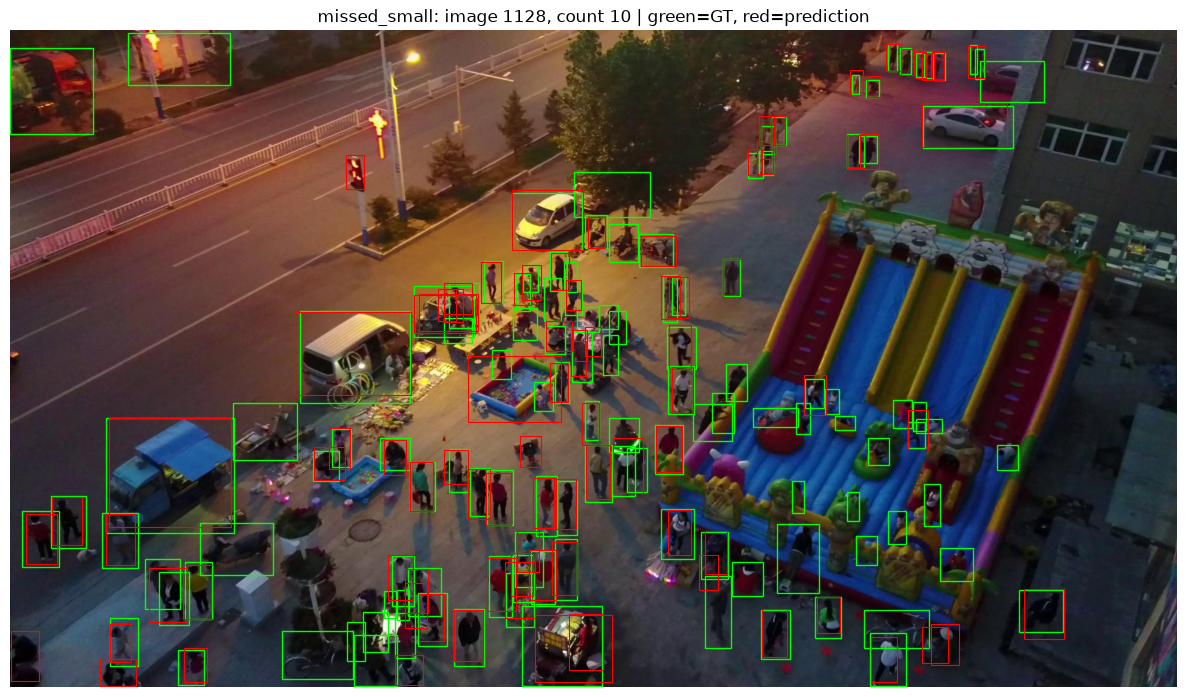

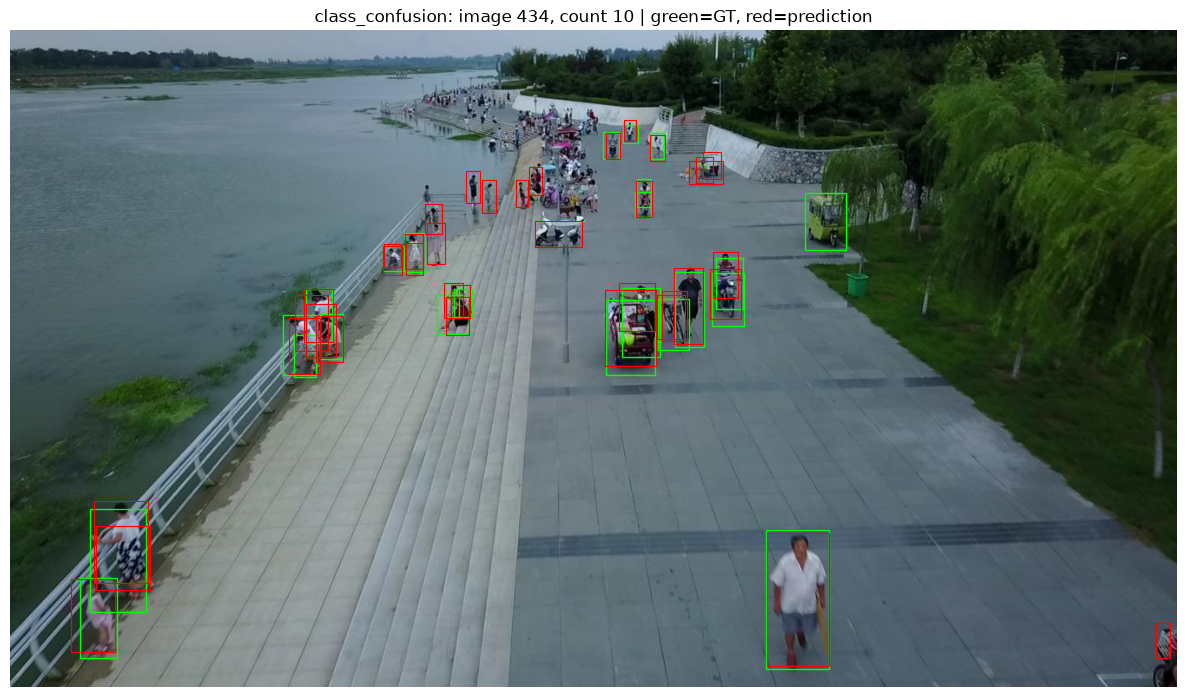

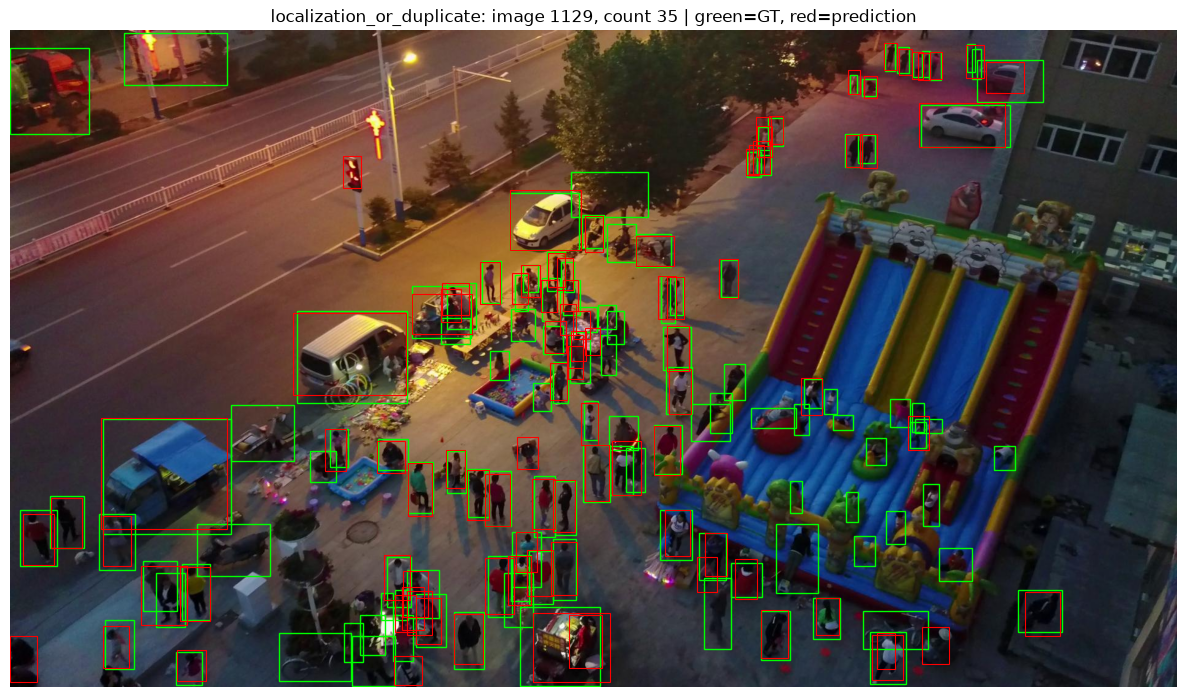

Saved diagnostics to H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\faster_rcnn_final_audit


In [33]:
# Failure-case diagnostics on Fold 0 with the selected checkpoint.
# Uses matching by class and IoU >= 0.5. These are diagnostic counts,
# NOT COCO's full multi-IoU AP calculation.
import matplotlib.pyplot as plt
from torchvision.ops import box_iou

selected_row = cv.loc[(cv["configuration"] == "selected") & (cv["fold"] == 0)].iloc[0]
checkpoint = load_checkpoint_with_fallback(Path(selected_row["run_dir"]) / "best.pt")
model = build_faster_rcnn(checkpoint["identity"]["model"], pretrained=False).to(DEVICE)
model.load_state_dict(checkpoint["model"])
model.eval()
del checkpoint

# A reproducible, limited subset; increase to all Fold 0 frames if needed.
diagnostic_frames = train_frames.loc[train_frames["fold"].eq(0)].head(120)
ds = VisDroneDataset(diagnostic_frames)
cases = []
with torch.inference_mode():
    for idx in range(len(ds)):
        image, gt = ds[idx]
        pred = model([image.to(DEVICE)])[0]
        keep = pred["scores"].detach().cpu() >= 0.3
        pb = pred["boxes"].detach().cpu()[keep]
        pl = pred["labels"].detach().cpu()[keep]
        gb, gl = gt["boxes"], gt["labels"]
        iou = box_iou(gb, pb) if len(gb) and len(pb) else torch.zeros(len(gb), len(pb))
        same = gl[:, None].eq(pl[None, :]) if len(gb) and len(pb) else torch.zeros(len(gb), len(pb), dtype=torch.bool)
        matched = (iou >= 0.5) & same
        missed = int((~matched.any(dim=1)).sum()) if len(gb) else 0
        areas = (gb[:, 2] - gb[:, 0]) * (gb[:, 3] - gb[:, 1])
        missed_small = int(((~matched.any(dim=1)) & (areas < 32**2)).sum()) if len(gb) else 0
        class_confusion = int(((iou >= 0.5) & ~same).any(dim=1).sum()) if len(gb) and len(pb) else 0
        localization = int(((iou >= 0.1) & (iou < 0.5) & same).any(dim=1).sum()) if len(gb) and len(pb) else 0
        duplicate = int(((iou >= 0.5) & same).sum(dim=1).sub(1).clamp(min=0).sum()) if len(gb) and len(pb) else 0
        cases.append({"idx": idx, "image_id": int(gt["image_id"]), "missed_small": missed_small,
                      "class_confusion": class_confusion, "localization_or_duplicate": localization + duplicate,
                      "missed_total": missed})
        del pred
case_table = pd.DataFrame(cases)
case_table.to_csv(audit_dir / "failure_diagnostics.csv", index=False)

from matplotlib.patches import Rectangle
for metric in ("missed_small", "class_confusion", "localization_or_duplicate"):
    winner = case_table.sort_values([metric, "image_id"], ascending=[False, True]).iloc[0]
    image, gt = ds[int(winner["idx"])]
    with torch.inference_mode():
        pred = model([image.to(DEVICE)])[0]
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.imshow(image.permute(1, 2, 0).numpy())
    for box in gt["boxes"].numpy():
        x1, y1, x2, y2 = box
        ax.add_patch(Rectangle((x1,y1), x2-x1,y2-y1, fill=False, edgecolor="lime", linewidth=1))
    keep = pred["scores"].detach().cpu() >= 0.3
    for box in pred["boxes"].detach().cpu()[keep].numpy():
        x1,y1,x2,y2 = box
        ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1, fill=False, edgecolor="red", linewidth=0.8))
    ax.set_title(f"{metric}: image {int(winner['image_id'])}, count {int(winner[metric])} | green=GT, red=prediction")
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(audit_dir / f"failure_{metric}.png", dpi=160)
    plt.show()
    plt.close(fig)
del model
gc.collect()
torch.cuda.empty_cache()
print("Saved diagnostics to", audit_dir)


In [34]:
# Kaggle submission: selected Faster R-CNN, Fold 0 checkpoint.
# No retraining. Inference on ALL test images; one CSV row per image.
from pathlib import Path
from PIL import Image
from torchvision.transforms.functional import pil_to_tensor
import numpy as np
import pandas as pd
import torch
import gc

test_csv_candidates = [
    DATA_ROOT / "test_images.csv",
    DATA_ROOT / "data" / "test_images.csv",
]
test_csv = next((p for p in test_csv_candidates if p.is_file()), None)
assert test_csv is not None, f"Cannot find test_images.csv: {test_csv_candidates}"
test_table = pd.read_csv(test_csv, dtype={"image_id": str})
assert {"image_id", "file_name"}.issubset(test_table.columns)
assert test_table.image_id.is_unique, "Duplicate test image IDs"

def resolve_test_path(file_name):
    name = Path(str(file_name))
    options = [DATA_ROOT / name, DATA_ROOT / "test" / name, test_csv.parent / name]
    for path in options:
        if path.is_file():
            return path
    raise FileNotFoundError(f"Test image missing: {file_name}; tried {options}")

test_paths = [resolve_test_path(name) for name in test_table.file_name]
selected_fold0 = cv_results.loc[
    cv_results.configuration.eq("selected") & cv_results.fold.eq(0)
].iloc[0]
checkpoint_path = Path(selected_fold0.run_dir) / "best.pt"
checkpoint = load_checkpoint_with_fallback(checkpoint_path)
assert checkpoint is not None, f"Checkpoint missing: {checkpoint_path}"
model = build_faster_rcnn(checkpoint["identity"]["model"]).to(DEVICE)
model.load_state_dict(checkpoint["model"], strict=True)
model.eval()
del checkpoint
print("Checkpoint:", checkpoint_path)
print("Test frames:", len(test_paths))


Loaded checkpoint: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\faster_rcnn_6bb40977bf33_fold0\best.pt
Checkpoint: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\faster_rcnn_6bb40977bf33_fold0\best.pt
Test frames: 3811


In [35]:
# Inference with resumable per-image cache (safe to restart after interruption).
# The score threshold is applied AFTER model inference; 500 detections max.
import json, hashlib
from tqdm.auto import tqdm

submission_dir = RUNS_DIR / "faster_rcnn_submission"
submission_dir.mkdir(parents=True, exist_ok=True)
cache_dir = submission_dir / "selected_fold0_cache"
cache_dir.mkdir(exist_ok=True)
score_threshold = 0.01

manifest = {
    "checkpoint": str(checkpoint_path.resolve()),
    "checkpoint_size": checkpoint_path.stat().st_size,
    "test_csv": str(test_csv.resolve()),
    "image_ids": [str(x) for x in test_table.image_id],
    "score_threshold": score_threshold,
    "max_detections": 500,
}
manifest_path = cache_dir / "manifest.json"
if manifest_path.exists():
    assert json.loads(manifest_path.read_text(encoding="utf-8")) == manifest, (
        "Existing cache belongs to different test set or checkpoint. "
        "Use a fresh cache directory."
    )
else:
    manifest_path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")

with torch.inference_mode():
    for image_id, image_path in tqdm(
        zip(test_table.image_id, test_paths),
        total=len(test_paths), desc="Faster R-CNN test inference"
    ):
        image_id = str(image_id)
        cache_file = cache_dir / f"{image_id}.json"
        if cache_file.is_file():
            continue
        with Image.open(image_path) as image:
            image = image.convert("RGB")
            width, height = image.size
            tensor = pil_to_tensor(image).float().div_(255).to(DEVICE)
        output = model([tensor])[0]
        boxes = output["boxes"].detach().cpu().numpy()
        labels = output["labels"].detach().cpu().numpy()
        scores = output["scores"].detach().cpu().numpy()
        keep = np.flatnonzero(scores >= score_threshold)
        keep = keep[np.argsort(-scores[keep], kind="stable")[:500]]
        records = []
        for j in keep:
            x1, y1, x2, y2 = boxes[j]
            x1, x2 = np.clip([x1, x2], 0, width)
            y1, y2 = np.clip([y1, y2], 0, height)
            cls = int(labels[j])
            if not (1 <= cls <= 8 and x2 > x1 and y2 > y1):
                continue
            records.append([
                cls - 1, float(scores[j]), float(x1), float(y1),
                float(x2 - x1), float(y2 - y1)
            ])
        tmp = cache_file.with_suffix(".json.tmp")
        tmp.write_text(json.dumps(records), encoding="utf-8")
        tmp.replace(cache_file)
        del tensor, output

print("Inference complete.")


Faster R-CNN test inference: 100%|██████████| 3811/3811 [33:54<00:00,  1.87it/s]

Inference complete.


In [36]:
# Assemble the exact project submission schema: image_id, PredictionString.
# Each detection is: 0-based-class score x y width height (original pixel coordinates).
rows = []
total_detections = 0
for image_id in test_table.image_id:
    image_id = str(image_id)
    cache_file = cache_dir / f"{image_id}.json"
    assert cache_file.is_file(), f"Missing prediction for image {image_id}"
    detections = json.loads(cache_file.read_text(encoding="utf-8"))
    assert len(detections) <= 500
    for det in detections:
        cls, score, x, y, w, h = det
        assert 0 <= cls <= 7 and 0 <= score <= 1
        assert np.isfinite([cls, score, x, y, w, h]).all()
        assert x >= 0 and y >= 0 and w > 0 and h > 0
    total_detections += len(detections)
    prediction_string = " ".join(
        f"{int(cls)} {score:.4f} {x:.1f} {y:.1f} {w:.1f} {h:.1f}"
        for cls, score, x, y, w, h in detections
    )
    rows.append((image_id, prediction_string))

submission_path = submission_dir / "submission_faster_rcnn_selected_fold0.csv"
submission = pd.DataFrame(rows, columns=["image_id", "PredictionString"])
submission.to_csv(submission_path, index=False)
check = pd.read_csv(submission_path, keep_default_na=False)
assert check.columns.tolist() == ["image_id", "PredictionString"]
assert len(check) == len(test_table)
assert check.image_id.tolist() == test_table.image_id.astype(str).tolist()
assert check.PredictionString.map(lambda s: len(s.split()) % 6 == 0).all()
print("Saved:", submission_path)
print("Images:", len(check), "| Detections:", total_detections)
display(check.head())


Saved: H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs\faster_rcnn_submission\submission_faster_rcnn_selected_fold0.csv
Images: 3811 | Detections: 329027


,image_id,PredictionString
0,clip_001_0000001,0 0.9987 693.5 758.5 43.8 117.1 0 0.9986 1709....
1,clip_001_0000002,0 0.9990 692.1 760.2 45.1 122.9 0 0.9989 1714....
2,clip_001_0000003,0 0.9992 685.9 768.2 45.3 119.1 0 0.9983 715.0...
3,clip_001_0000004,0 0.9990 1720.8 805.1 63.6 150.1 0 0.9976 1663...
4,clip_001_0000005,0 0.9985 1714.8 816.8 58.3 152.0 0 0.9982 1658...


In [38]:
import torch
from pathlib import Path
from pprint import pprint

runs = Path(
    r"H:\UCU\3_year\sem_1\artificial_intelligence\hw2\runs"
)

for path in sorted(runs.glob("retinanet_*_fold0/best.pt")):
    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False,
    )

    print(f"\n{'=' * 70}")
    print(path.parent.name)

    identity = checkpoint.get("identity", {})
    pprint(identity.get("model", {}))
    pprint(identity.get("training", {}))